In [4]:
# --- Cell 1: Setup and Imports ---
import os
import sys
import torch
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
import soundfile as sf
import yaml
from matplotlib.colors import LinearSegmentedColormap

# Setup project root (adjust if your notebook is inside a 'notebooks' folder)
if os.path.basename(os.getcwd()) == 'notebooks':
    PROJECT_ROOT = os.path.dirname(os.getcwd())
else:
    PROJECT_ROOT = os.getcwd()
sys.path.append(PROJECT_ROOT)

from src.dataset import MaestroDataset
from src.models import PedalNet, PedalMechanism, AcousticModel

# Set plot style for publication
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 14,
    'axes.titlesize': 16,
    'legend.fontsize': 12,
    'figure.dpi': 300 # High resolution for paper
})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [5]:
# --- Cell 2: Load Models and Find a Good Audio Segment ---
config_path = os.path.join(PROJECT_ROOT, 'configs', 'default.yaml')
ckpt_path = os.path.join(PROJECT_ROOT, 'checkpoints', 'best_pedal_net.pth')

with open(config_path, 'r') as f:
    cfg = yaml.safe_load(f)

# 1. Load Models
brain = PedalNet(1, 1).to(device)
brain.load_state_dict(torch.load(ckpt_path, map_location=device)['model_state_dict'])
brain.eval()

mechanism = PedalMechanism(sr=16000, hop_length=160).to(device)
acoustics = AcousticModel(sr=16000).to(device)

# 2. Load Dataset
data_root = os.path.join(PROJECT_ROOT, cfg['data']['root_dir'])
dry_root = os.path.join(PROJECT_ROOT, cfg['data']['dry_dir'])

dataset = MaestroDataset(root_dir=data_root, dry_dir=dry_root, split='test', segment_seconds=5.0)

# 3. Find a "Golden Segment" (High pedal activity for good visualization)
print("Searching for a segment with dynamic pedal usage...")
best_idx = 0
max_transitions = 0
golden_sample = None

# Scan a few samples to find one with lots of pedal presses/releases
for idx in range(min(50, len(dataset))):
    sample = dataset[idx]
    pedal = sample['pedal'].squeeze().numpy()
    # Count transitions (0->1 or 1->0)
    transitions = np.sum(np.abs(np.diff(pedal > 0.5)))
    if transitions > max_transitions and transitions < 15: # Not too chaotic
        max_transitions = transitions
        best_idx = idx
        golden_sample = sample

print(f"Found Golden Sample at index {best_idx} with {max_transitions} pedal transitions.")

audio_dry = golden_sample['audio'].to(device).unsqueeze(0)
pedal_gt = golden_sample['pedal'].numpy().flatten()

Searching for a segment with dynamic pedal usage...
Found Golden Sample at index 36 with 14 pedal transitions.


In [6]:
# --- Cell 3: Run Inference Pipeline (Updated for Final Physics) ---
import torchaudio.transforms as T
import torch.nn.functional as F

mel_trans = T.MelSpectrogram(sample_rate=16000, n_fft=2048, hop_length=160, n_mels=229).to(device)

with torch.no_grad():
    # 1. Perception
    melspec = torch.log(mel_trans(audio_dry) + 1e-9)
    probs = brain(melspec)
    
    # 2. Mechanism (LCAST & Inertia)
    mech = mechanism(probs)
    
    target_len = audio_dry.shape[-1]
    pos = torch.nn.functional.interpolate(mech['position'], size=target_len, mode='linear')
    press = torch.nn.functional.interpolate(mech['press_gain'], size=target_len, mode='linear')
    rel = torch.nn.functional.interpolate(mech['release_gain'], size=target_len, mode='linear')
    
    # 3. Acoustics (Dual-Stage Decay Physics)
    torch.manual_seed(42) 
    resonance = acoustics(audio_dry, pos)
    
    # Low-pass Rumble Noise to prevent aliasing visuals
    raw_noise = torch.randn_like(audio_dry)
    rumble_noise = F.avg_pool1d(raw_noise, kernel_size=99, stride=1, padding=49)
    rumble_noise = rumble_noise / (torch.max(torch.abs(rumble_noise)) + 1e-9)
    mech_noise = (rumble_noise * press) + (rumble_noise * rel)
    
    # Final Mix & Peak Limiter
    wet_audio = audio_dry + resonance * 1.0 + mech_noise * 0.01
    
    max_val = torch.max(torch.abs(wet_audio))
    if max_val > 0.99:
        wet_audio = wet_audio / max_val * 0.95
        
# Convert to numpy
audio_dry_np = audio_dry.squeeze().cpu().numpy()
audio_wet_np = wet_audio.squeeze().cpu().numpy()
probs_np = probs.squeeze().cpu().numpy()
pos_np = pos.squeeze().cpu().numpy()

time_axis_audio = np.linspace(0, 5.0, len(audio_dry_np))
time_axis_frames = np.linspace(0, 5.0, len(probs_np))

print("Inference Complete. Ready to plot.")

Inference Complete. Ready to plot.


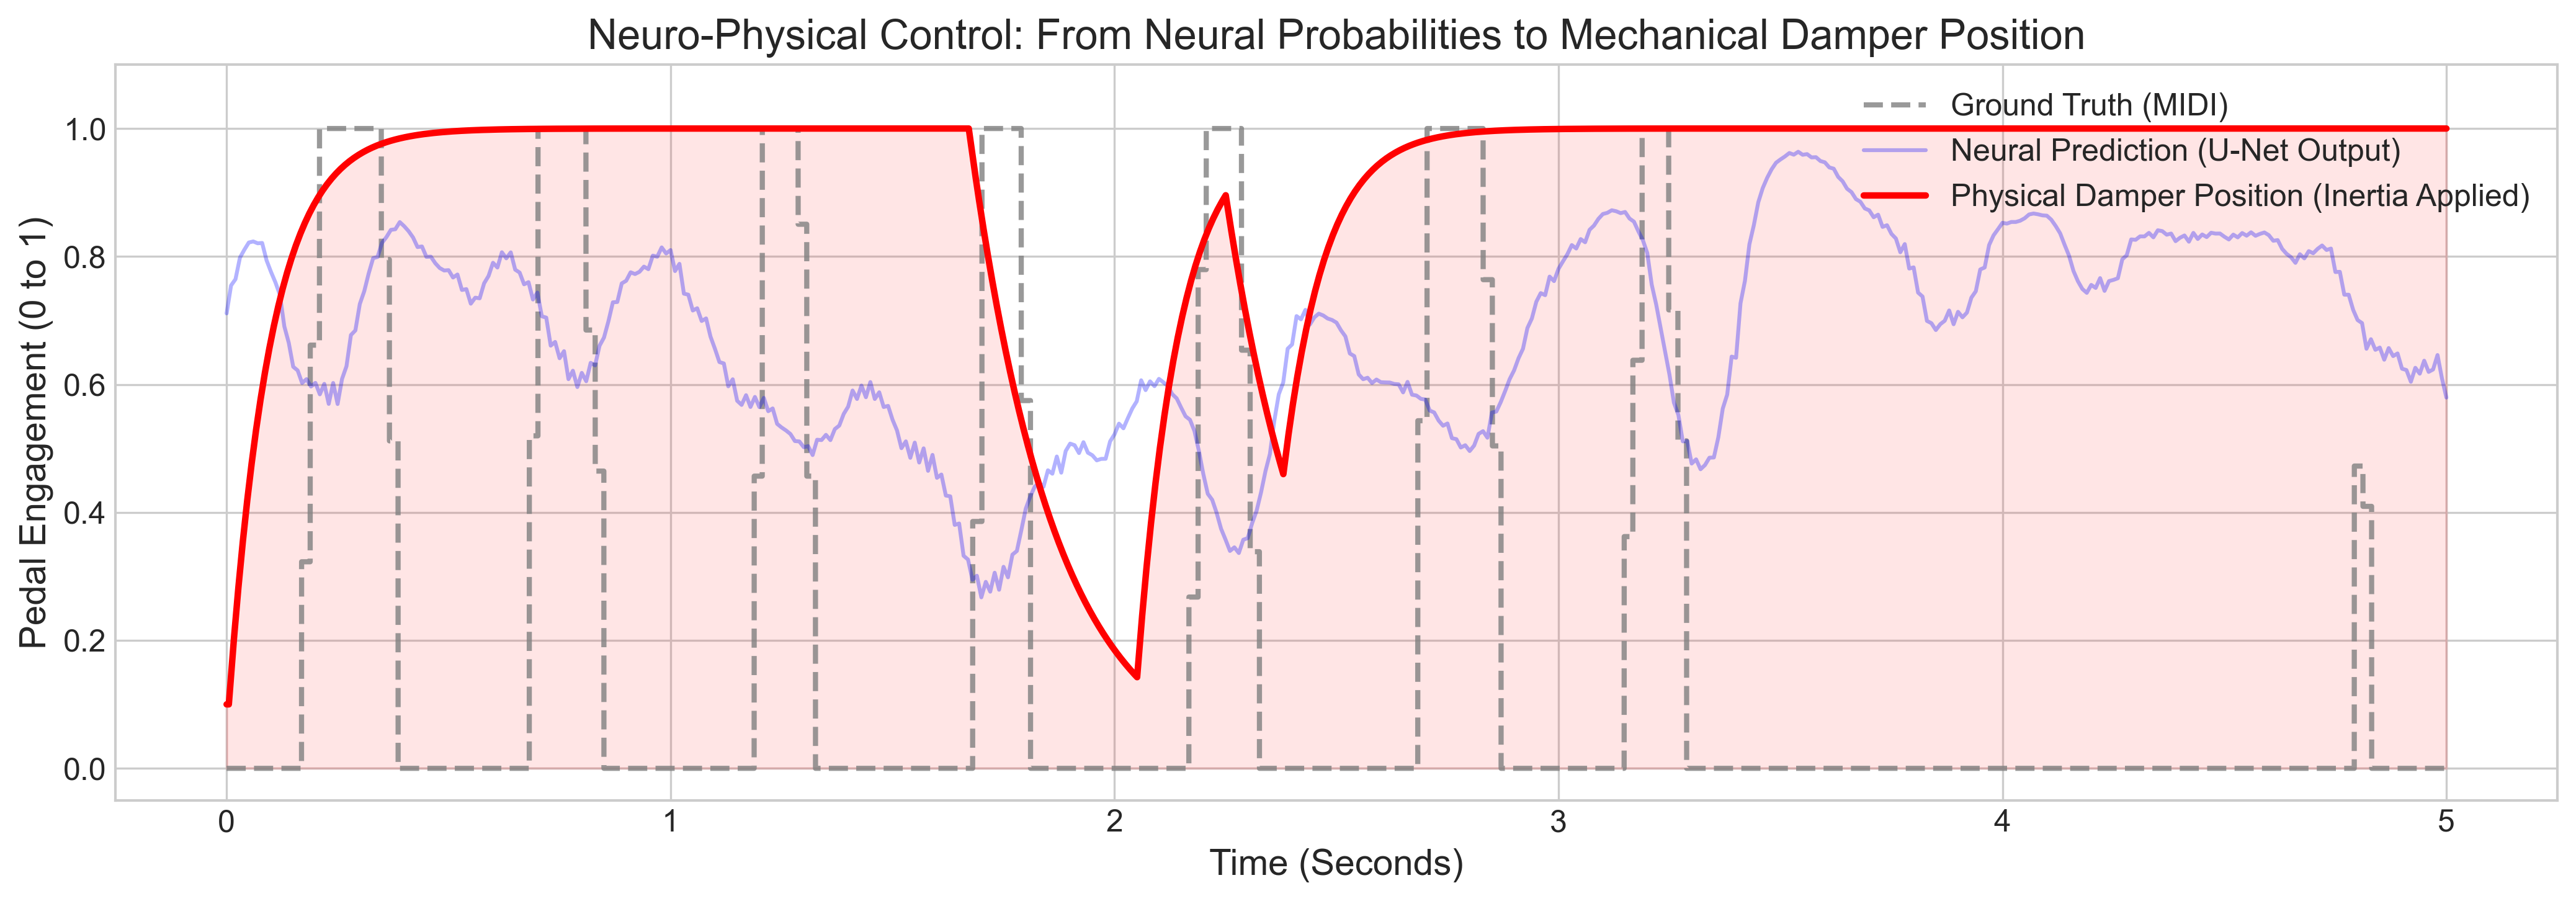

In [7]:
# --- Cell 4: Figure 1 - Control Logic & Mechanical Inertia ---
plt.figure(figsize=(14, 5))

# Plot Ground Truth
plt.plot(np.linspace(0, 5.0, len(pedal_gt)), pedal_gt, 
         label='Ground Truth (MIDI)', color='grey', linestyle='--', linewidth=2, alpha=0.8)

# Plot Neural Prediction (Raw Probabilities)
plt.plot(time_axis_frames, probs_np, 
         label='Neural Prediction (U-Net Output)', color='blue', alpha=0.3)

# Plot Physical Position (After Schmitt Trigger & Inertia)
plt.plot(time_axis_audio, pos_np, 
         label='Physical Damper Position (Inertia Applied)', color='red', linewidth=2.5)

plt.fill_between(time_axis_audio, 0, pos_np, color='red', alpha=0.1)

plt.title("Neuro-Physical Control: From Neural Probabilities to Mechanical Damper Position")
plt.xlabel("Time (Seconds)")
plt.ylabel("Pedal Engagement (0 to 1)")
plt.legend(loc='upper right')
plt.ylim(-0.05, 1.1)
plt.tight_layout()

plt.savefig("fig_control_inertia.pdf", bbox_inches='tight')
plt.show()

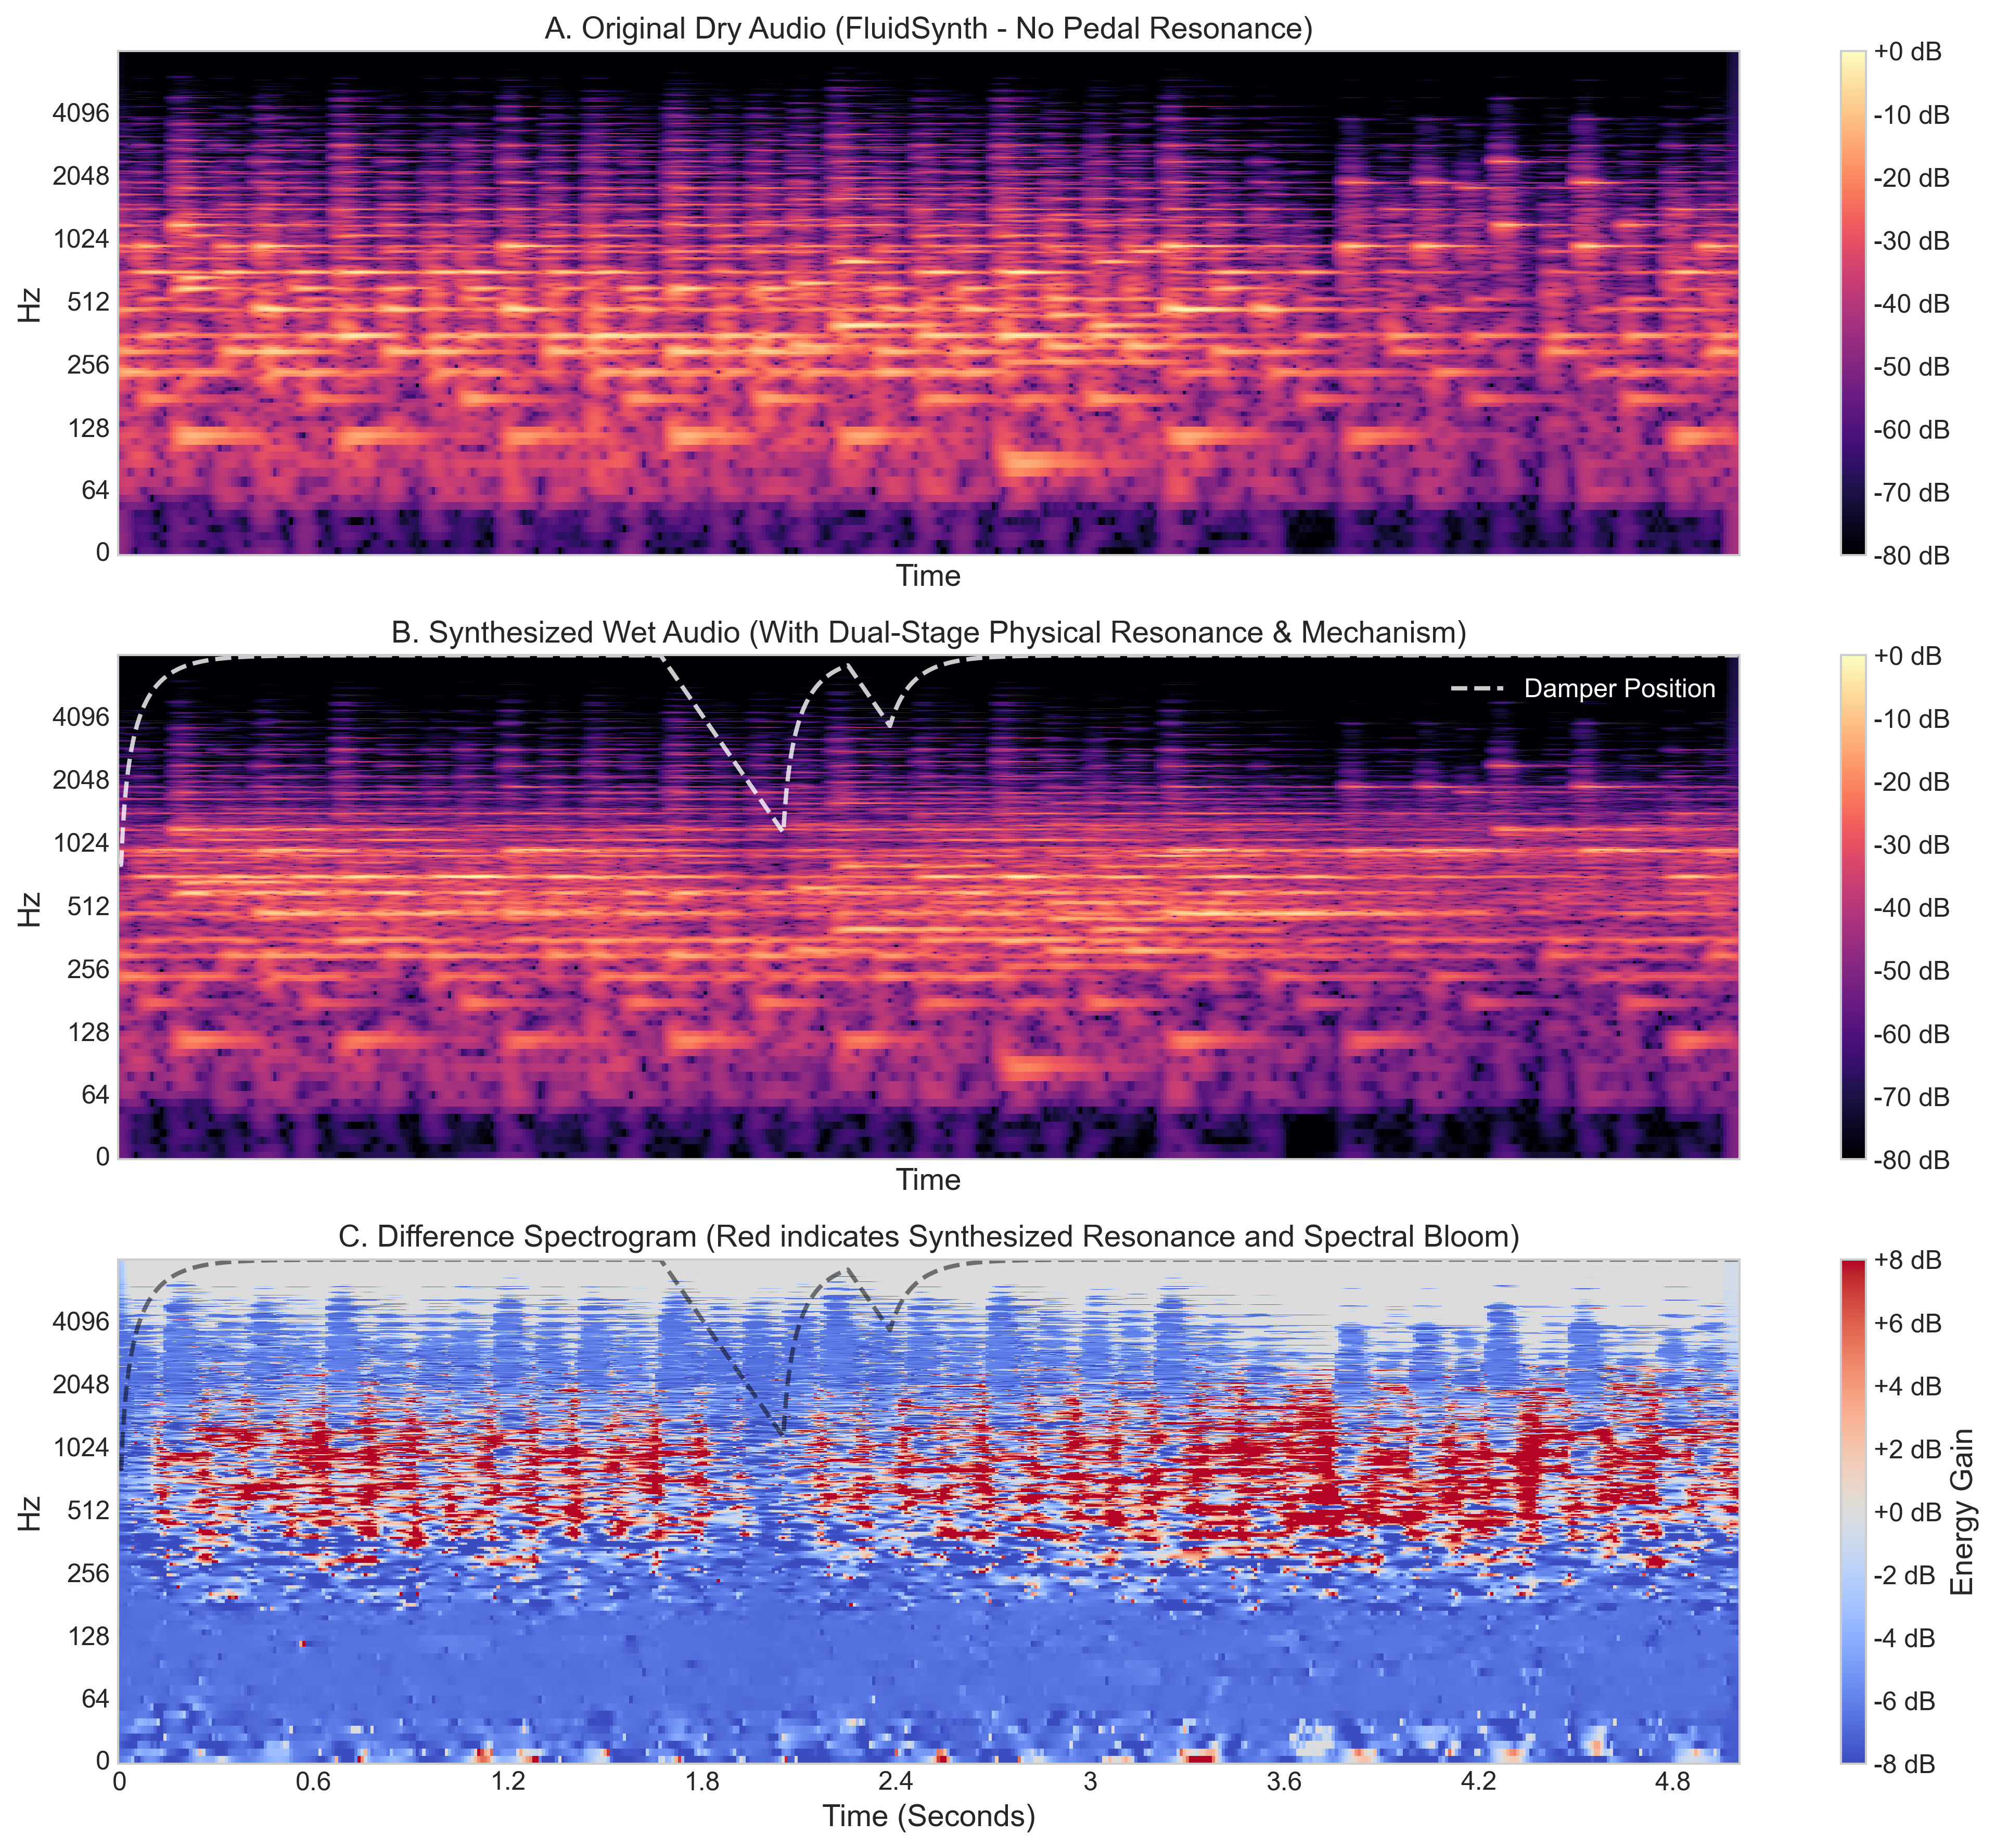

In [8]:
# --- Cell 5: Figure 2 - Spectral Bloom and Acoustic Synthesis ---
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

n_fft = 2048
hop_length = 160
sr = 16000

# 1. Calculate Spectrograms
D_dry = librosa.amplitude_to_db(np.abs(librosa.stft(audio_dry_np, n_fft=n_fft, hop_length=hop_length)), ref=np.max)
D_wet = librosa.amplitude_to_db(np.abs(librosa.stft(audio_wet_np, n_fft=n_fft, hop_length=hop_length)), ref=np.max)

# Calculate difference
min_len = min(D_dry.shape[1], D_wet.shape[1])
D_diff = D_wet[:, :min_len] - D_dry[:, :min_len]

# Plot A: Dry Audio
ax1 = axes[0]
img1 = librosa.display.specshow(D_dry, y_axis='log', x_axis='time', sr=sr, hop_length=hop_length, ax=ax1, cmap='magma')
ax1.set_title("A. Original Dry Audio (FluidSynth - No Pedal Resonance)", fontsize=14)
fig.colorbar(img1, ax=ax1, format="%+2.0f dB")

# Plot B: Wet Audio (Ours)
ax2 = axes[1]
img2 = librosa.display.specshow(D_wet, y_axis='log', x_axis='time', sr=sr, hop_length=hop_length, ax=ax2, cmap='magma')
ax2.plot(time_axis_audio, pos_np * sr/2, color='white', linewidth=2, linestyle='--', alpha=0.8, label='Damper Position')
ax2.set_title("B. Synthesized Wet Audio (With Dual-Stage Physical Resonance & Mechanism)", fontsize=14)
ax2.legend(loc='upper right', facecolor='black', labelcolor='white')
fig.colorbar(img2, ax=ax2, format="%+2.0f dB")

# Plot C: Difference (The "Bloom" Effect)
ax3 = axes[2]
# High-sensitivity visualization mapping (vmax=8) to capture fine physical harmonics
vmax = 8 
img3 = librosa.display.specshow(D_diff, y_axis='log', x_axis='time', sr=sr, hop_length=hop_length, ax=ax3, cmap='coolwarm', vmin=-vmax, vmax=vmax)
ax3.plot(time_axis_audio, pos_np * sr/2, color='black', linewidth=2, linestyle='--', alpha=0.5)
ax3.set_title("C. Difference Spectrogram (Red indicates Synthesized Resonance and Spectral Bloom)", fontsize=14)
fig.colorbar(img3, ax=ax3, format="%+2.0f dB", label="Energy Gain")

plt.xlabel("Time (Seconds)")
plt.tight_layout()

plt.savefig("fig_spectral_bloom_final.pdf", bbox_inches='tight')
plt.show()